# Round Win Probability — Training Notebook

Trains all models on a single map's preprocessed dataset.
Edit the **two config blocks** in Section 0 (map name + tournament split) and run top-to-bottom.

**Models trained:**
- Baselines: Constant predictor, Health-difference predictor (τ fitted on val)
- Vector: LightGBM
- Set: DeepSets, SetTransformer
- Graph: GCNSimple, GAT
- Temporal: TemporalGNN (Section 9 — separate session)

**NNConv GCN excluded** — confirmed negative result on de_dust2, not retrained.

---
Sections: 0 Config | 1 Data | 2 Datasets | 3 Models | 4 Helpers | 5 Train | 6 Reload | 7 Results | 8 Plots | 9 TemporalGNN

## 0. Imports & Config

In [1]:
!pip install torch_geometric -q


In [2]:
import os, json, random, time, warnings
from pathlib import Path
from copy import deepcopy

import numpy as np
import pandas as pd
import scipy.optimize
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam
from torch_geometric.data import Data, Batch
from torch_geometric.loader import DataLoader as PyGLoader
from torch_geometric.nn import GCNConv, GATConv, NNConv, global_mean_pool, BatchNorm
from torch_geometric.utils import dropout_edge
import lightgbm as lgb
from sklearn.metrics import log_loss
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

warnings.filterwarnings('ignore')

from google.colab import drive
drive.mount('/content/drive')

import sys
BASE = Path('/content/drive/MyDrive/magisterka')
sys.path.insert(0, str(BASE))

from dataset import (
    load_processed_matches, flatten_to_states,
    VectorDataset, SetDataset, SetNormaliser,
    GraphDataset, TemporalGraphDataset, temporal_collate_fn,
    build_datasets,
)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda


### ✏️ Edit here — map name

In [3]:
# ── MAP CONFIGURATION ────────────────────────────────────────────────────
MAP_NAME = 'overpass'   # change per map

PROCESSED_DIR  = BASE / 'data'        / MAP_NAME
CHECKPOINT_DIR = BASE / 'checkpoints' / MAP_NAME
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

S1_DIR = PROCESSED_DIR / 'season1'
S2_DIR = PROCESSED_DIR / 'season2'

print(f'Map:            de_{MAP_NAME}')
print(f'Checkpoint dir: {CHECKPOINT_DIR}')
print(f'Season 1 exists: {S1_DIR.exists()}')
print(f'Season 2 exists: {S2_DIR.exists()}')

# ── Hyperparameters ───────────────────────────────────────────────────────
# Neural model settings match ESTA paper (Xenopoulos & Silva, 2022):
#   lr=1e-3, batch_size=32, epochs=100, early_stopping=10
# LightGBM uses tuned params (num_leaves=63, lr=0.05, feature_fraction=0.9)
# rather than ESTA's LGBMClassifier defaults — these are strictly better.
CFG = dict(
    hidden             = 128,
    batch_size         = 32,      # ESTA: 32
    lr                 = 1e-3,    # ESTA: 0.001
    lr_temporal        = 3e-4,
    weight_decay       = 1e-4,
    grad_clip          = 1.0,
    grad_clip_temporal = 0.5,
    epochs             = 100,     # ESTA: 100
    patience           = 10,      # ESTA: early_stopping_rounds=10
    ece_bins           = 10,
    max_seq_len        = 80,
)

# ── Graph-model overrides (combat overfitting) ────────────────────────────
# Graph models on a single map (~313 training matches) overfit much faster
# than set/vector models. The overrides below are applied in the training
# cells; CFG remains unchanged so baselines and set models are unaffected.
#
#   hidden_graph   : 64 instead of 128 — halves parameter count; the fully-
#                    connected 10-node graph is already expressive at 64-dim.
#   dropout_graph  : 0.5 instead of 0.3 — stronger regularisation on conv
#                    layers where overfitting originates.
#   drop_edge_p    : 0.5 instead of 0.3 — stochastically removes half the
#                    edges per step, preventing reliance on any single path.
#   weight_decay_graph : 1e-3 instead of 1e-4 — heavier L2 penalty.
#   patience_graph : 5 instead of 10 — best ckpt appears at ep 1-3;
#                    10-epoch patience wastes compute and can drift.
#   lr_warmup_gat  : GAT attention weights are unstable at a cold lr=1e-3;
#                    warm up for 5 epochs at lr=1e-4, then step to 1e-3.
GRAPH_CFG = dict(
    hidden         = 64,
    dropout_gcn    = 0.5,   # GCNSimple: higher dropout tolerated
    dropout_gat    = 0.3,
    drop_edge_p    = 0.5,
    weight_decay   = 1e-3,
    patience       = 5,
    lr_warmup_gat  = 1e-4,
    warmup_epochs  = 5,
)
print(f'CFG:       {CFG}')
print(f'GRAPH_CFG: {GRAPH_CFG}')


Map:            de_overpass
Checkpoint dir: /content/drive/MyDrive/magisterka/checkpoints/overpass
Season 1 exists: True
Season 2 exists: True
CFG:       {'hidden': 128, 'batch_size': 32, 'lr': 0.001, 'lr_temporal': 0.0003, 'weight_decay': 0.0001, 'grad_clip': 1.0, 'grad_clip_temporal': 0.5, 'epochs': 100, 'patience': 10, 'ece_bins': 10, 'max_seq_len': 80}
GRAPH_CFG: {'hidden': 64, 'dropout_gcn': 0.5, 'dropout_gat': 0.3, 'drop_edge_p': 0.5, 'weight_decay': 0.001, 'patience': 5, 'lr_warmup_gat': 0.0001, 'warmup_epochs': 5}


## 1. Data Loading & Splitting

In [4]:
from tqdm import tqdm

def get_tournament(match_key: str) -> str:
    parts = match_key.split('_')
    for i in range(len(parts) - 1, 0, -1):
        if '-vs-' in parts[i]:
            return '_'.join(parts[:i])
    return parts[0]

def load_season(season_dir: Path) -> dict:
    data = {}
    if not season_dir.exists():
        print(f'  ⚠️  {season_dir} not found — skipping')
        return data
    for fname in tqdm(sorted(season_dir.glob('*.json')), desc=str(season_dir.name)):
        with open(fname) as f:
            data.update(json.load(f))
    return data

print('Loading data...')
s1_data = load_season(S1_DIR)
s2_data = load_season(S2_DIR)
print(f'Season 1: {len(s1_data):,} matches')
print(f'Season 2: {len(s2_data):,} matches')

s2_tournaments = sorted({get_tournament(k) for k in s2_data})
print(f'\nSeason 2 tournaments ({len(s2_tournaments)} total):')
for t in s2_tournaments:
    n = sum(1 for k in s2_data if get_tournament(k) == t)
    print(f'  {n:3d} matches  |  {t}')


Loading data...
  ⚠️  /content/drive/MyDrive/magisterka/data/overpass/season1 not found — skipping


season2: 100%|██████████| 99/99 [01:56<00:00,  1.18s/it]

Season 1: 0 matches
Season 2: 99 matches

Season 2 tournaments (24 total):
    5 matches  |  BLAST Bounty Season 2
    1 matches  |  BLAST Bounty Season 2 Finals
    4 matches  |  BLAST Open London
    1 matches  |  BLAST Open London Finals
    5 matches  |  BLAST Rivals Season 2
    1 matches  |  BLAST Rivals Season 2 Playoffs
    4 matches  |  CS Asia Championships
    2 matches  |  ESL Pro League Playoffs
   13 matches  |  ESL Pro League Stage 1
    9 matches  |  ESL Pro League Stage 2
    4 matches  |  Esports World Cup
    6 matches  |  FISSURE Playground 2
    1 matches  |  FISSURE Playground 2 Playoffs
    8 matches  |  IEM Chengdu
    2 matches  |  IEM Chengdu Playoffs
    3 matches  |  IEM Cologne
    4 matches  |  IEM Cologne Stage 1
    5 matches  |  PGL Masters Bucharest
    3 matches  |  PGL Masters Bucharest Playoffs
    1 matches  |  StarLadder Major Playoffs
    5 matches  |  StarLadder Major Stage 1
    3 matches  |  StarLadder Major Stage 2
    5 matches  |  StarLadde

### ✏️ Edit here — tournament split

In [7]:
# TOURNAMENT_SPLIT = {
#     # ── TRAIN ────────────────────────────────
#     'StarLadder StarSeries Fall':       'train',
#     'BLAST Bounty Season 2':            'train',
#     'BLAST Bounty Season 2 Finals':     'train',
#     'BLAST Open London':                'train',
#     'BLAST Open London Finals':         'train',
#     'Esports World Cup':                'train',
#     'FISSURE Playground 2':             'train',
#     'FISSURE Playground 2 Playoffs':    'train',
#     'IEM Cologne':                      'train',
#     'IEM Cologne Stage 1':              'train',
#     'IEM Cologne Playoffs':             'train',
#     'ESL Pro League Stage 1':           'train',
#     # ── VAL ──────────────────────────────────
#     'ESL Pro League Stage 2':           'val',
#     'ESL Pro League Playoffs':          'val',
#     'CS Asia Championships':            'val',
#     'CS Asia Championships Playoffs':   'val',
#     'IEM Chengdu':                      'val',
#     'IEM Chengdu Playoffs':             'val',
#     'PGL Masters Bucharest':            'val',
#     'PGL Masters Bucharest Playoffs':   'val',
#     'Thunderpick World Championship':   'val',
#     'BLAST Rivals Season 2':            'val',
#     'BLAST Rivals Season 2 Playoffs':   'val',
#     # ── TEST (StarLadder Major) ───────────────
#     'StarLadder Major Stage 1':         'test',
#     'StarLadder Major Stage 2':         'test',
#     'StarLadder Major Stage 3':         'test',
#     'StarLadder Major Playoffs':        'test',
# }
# TOURNAMENT_SPLIT = {
#    "BLAST Bounty Season 1": "train",
#    "BLAST Bounty Season 1 Finals": "train",
#    "IEM Katowice Play-in": "train",
#    "IEM Katowice": "train",
#    "IEM Katowice Playoffs": "train",
#    "PGL Cluj-Napoca": "train",
#    "ESL Pro League Season 21 Stage 1": "train",
#    "ESL Pro League Season 21 Stage 2": "train",
#   "ESL Pro League Season 21 Playoffs": "train",
#    "BLAST Open Lisbon": "train",
#    "BLAST Open Lisbon Playoffs":"train",
# "PGL Bucharest": "train",
#    "PGL Bucharest Playoffs": "train",
#    "YaLLa Compass Groups":"train",
#    "YaLLa Compass Playoffs":"train",
#     "IEM Melbourne": "train",
#    "IEM Melbourne Playoffs": "train",
#    "CCT Global Finals":"train",
#   "MESA Nomadic Masters Groups":"train",
#     "BLAST Rivals Season 1 Groups": "train",
#    "BLAST Rivals Season 1 Playoffs": "train",
#    "Asian Champions League":"train",

#     "PGL Astana": "val",
#    "PGL Astana Playoffs": "val",
#     "IEM Dallas": "val",
#    "BLAST Major Stage 1": "val",

#    "BLAST Major Stage 2": "test",
#    "BLAST Major": "test",
#    "BLAST Major Playoffs": "test",
#    "FISSURE Playground 1": "test",
#    "FISSURE Playground 1 Playoffs": "test",
# }


TOURNAMENT_SPLIT = {
    'StarLadder StarSeries Fall':       'train',
    'BLAST Bounty Season 2':            'train',
    'BLAST Bounty Season 2 Finals':     'train',
    'BLAST Open London':                'train',
    'BLAST Open London Finals':         'train',
    'Esports World Cup':                'train',
    'FISSURE Playground 2':             'train',
    'FISSURE Playground 2 Playoffs':    'train',
    'IEM Cologne':                      'train',
    'IEM Cologne Stage 1':              'train',
    'IEM Cologne Playoffs':             'train',
    'ESL Pro League Stage 1':           'train',
    'ESL Pro League Stage 2':           'train',
    'ESL Pro League Playoffs':          'train',
    'CS Asia Championships':            'train',
    'CS Asia Championships Playoffs':   'train',
    'IEM Chengdu':                      'train',
    'IEM Chengdu Playoffs':             'train',
    'PGL Masters Bucharest':            'val',
    'PGL Masters Bucharest Playoffs':   'val',
    'Thunderpick World Championship':   'val',
    'BLAST Rivals Season 2':            'val',
    'BLAST Rivals Season 2 Playoffs':   'val',
    'StarLadder Major Stage 1':         'test',
    'StarLadder Major Stage 2':         'test',
    'StarLadder Major Stage 3':         'test',
    'StarLadder Major Playoffs':        'test',
}


train_data, val_data, test_data = dict(s1_data), {}, {}
unassigned = []
for key, match in s2_data.items():
    t = get_tournament(key)
    split = TOURNAMENT_SPLIT.get(t)
    if   split == 'train': train_data[key] = match
    elif split == 'val':   val_data[key]   = match
    elif split == 'test':  test_data[key]  = match
    else:                  unassigned.append((t, key))

if unassigned:
    print(f'⚠️  {len(unassigned)} unassigned — add to TOURNAMENT_SPLIT:')
    for t, _ in sorted(set((t, '') for t, _ in unassigned)): print(f'   {t}')

def count_rounds(d): return sum(len({r.get('roundNum') for r in v['df']}) for v in d.values())
def count_states(d): return sum(len(v['Y']) for v in d.values())

print(f'\n=== Split Summary — de_{MAP_NAME} ===')
for name, d in [('Train', train_data), ('Val', val_data), ('Test', test_data)]:
    print(f'  {name:<5}: {len(d):4d} matches | {count_rounds(d):>6,} rounds | {count_states(d):>10,} states')



=== Split Summary — de_overpass ===
  Train:   67 matches |  1,478 rounds |    176,551 states
  Val  :   18 matches |    359 rounds |     42,231 states
  Test :   14 matches |    308 rounds |     37,006 states


## 2. Dataset Construction

In [8]:
datasets = build_datasets(
    train_data, val_data, test_data,
    temporal=False,
    max_seq_len=CFG['max_seq_len'],
)
normaliser_path = CHECKPOINT_DIR / 'normaliser'
datasets['set']['normaliser'].save(str(normaliser_path))
print(f'Datasets ready. Normaliser saved → {normaliser_path}.npz')


Datasets ready. Normaliser saved → /content/drive/MyDrive/magisterka/checkpoints/overpass/normaliser.npz


## 3. Model Definitions

### 3.1 DeepSets

In [9]:
class DeepSets(nn.Module):
    """
    DeepSets (Zaheer et al., 2017).
    Hyperparameters consistent with ESTA paper:
      lr=1e-3, batch_size=32, epochs=100, early_stopping=10.
    hidden=128 (our extension; ESTA used 64 — increased for richer representation).
    Dropout=0.3 added to regularise against correlated game states.
    """
    def __init__(self, in_features=32, hidden=128, dropout=0.3):
        super().__init__()
        self.phi = nn.Sequential(
            nn.Linear(in_features, hidden), nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, hidden),
        )
        self.rho = nn.Sequential(
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, x):
        return self.rho(self.phi(x).mean(dim=1))


### 3.2 SetTransformer

In [10]:
class MultiheadAttentionBlock(nn.Module):
    def __init__(self, d_model, num_heads, dropout=0.1):
        super().__init__()
        self.attn  = nn.MultiheadAttention(d_model, num_heads, batch_first=True, dropout=dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.ff    = nn.Sequential(nn.Linear(d_model, d_model), nn.ReLU(),
                                   nn.Dropout(dropout), nn.Linear(d_model, d_model))
        self.norm2 = nn.LayerNorm(d_model)

    def forward(self, x):
        attn_out, _ = self.attn(x, x, x)
        x = self.norm1(x + attn_out)
        return self.norm2(x + self.ff(x))


class InducedSetAttentionBlock(nn.Module):
    def __init__(self, d_model, num_heads, num_inds=4, dropout=0.1):
        super().__init__()
        self.I    = nn.Parameter(torch.randn(1, num_inds, d_model))
        self.mab0 = MultiheadAttentionBlock(d_model, num_heads, dropout)
        self.mab1 = MultiheadAttentionBlock(d_model, num_heads, dropout)

    def forward(self, x):
        B = x.size(0)
        H = self.mab0(torch.cat([self.I.expand(B, -1, -1), x], dim=1))[:, :self.I.size(1)]
        return self.mab1(torch.cat([x, H], dim=1))[:, :x.size(1)]


class PoolingByMultiheadAttention(nn.Module):
    def __init__(self, d_model, num_heads, k=1, dropout=0.1):
        super().__init__()
        self.S   = nn.Parameter(torch.randn(1, k, d_model))
        self.mab = MultiheadAttentionBlock(d_model, num_heads, dropout)

    def forward(self, x):
        B = x.size(0)
        return self.mab(torch.cat([self.S.expand(B, -1, -1), x], dim=1))[:, :self.S.size(1)]


class SetTransformer(nn.Module):
    """
    Set Transformer (Lee et al., 2019).
    Hyperparameters consistent with ESTA paper:
      lr=1e-3, batch_size=32, epochs=100, early_stopping=10.
    num_heads=1, num_inds=4 (ESTA defaults).
    """
    def __init__(self, in_features=32, hidden=128, num_heads=1, num_inds=4, dropout=0.1):
        super().__init__()
        self.embed   = nn.Linear(in_features, hidden)
        self.encoder = InducedSetAttentionBlock(hidden, num_heads, num_inds, dropout)
        self.decoder = PoolingByMultiheadAttention(hidden, num_heads, k=1, dropout=dropout)
        self.head    = nn.Sequential(nn.Dropout(dropout), nn.Linear(hidden, 1))

    def forward(self, x):
        x = F.relu(self.embed(x))
        x = self.encoder(x)
        x = self.decoder(x).squeeze(1)
        return self.head(x)


### 3.3 GCNSimple

In [11]:
class GCNSimple(nn.Module):
    """
    Two-layer GCN with scalar edge weights (Kipf & Welling, 2017).
    Edge features: inv_geodesic_dist as scalar weight; visibility + same_team
    mean-aggregated onto node features (node augmentation trick).

    Regularisation vs. original:
      - dropout     : 0.3 → 0.5  (conv layers are the overfitting hotspot)
      - drop_edge_p : 0.3 → 0.5  (forces reliance on multiple graph paths)
      - hidden      : 128 → 64   (halves parameters; set via GRAPH_CFG)
    """
    def __init__(self, hidden=64, num_node_features=32, dropout=0.5, drop_edge_p=0.5):
        super().__init__()
        self.drop_edge_p = drop_edge_p
        self.conv1 = GCNConv(num_node_features + 2, hidden)
        self.bn1   = BatchNorm(hidden)
        self.conv2 = GCNConv(hidden, hidden)
        self.bn2   = BatchNorm(hidden)
        self.mlp   = nn.Sequential(
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, data):
        x, ei, ea, batch = data.x, data.edge_index, data.edge_attr, data.batch
        if self.training:
            ei, edge_mask = dropout_edge(ei, p=self.drop_edge_p, training=True)
            ea = ea[edge_mask]
        n   = x.size(0)
        src = ei[0]
        vis_agg  = torch.zeros(n, 1, device=x.device)
        team_agg = torch.zeros(n, 1, device=x.device)
        count    = torch.zeros(n, 1, device=x.device)
        ones     = torch.ones(src.size(0), 1, device=x.device)
        vis_agg.scatter_add_(0, src.unsqueeze(1), ea[:, 1].unsqueeze(1))
        team_agg.scatter_add_(0, src.unsqueeze(1), ea[:, 2].unsqueeze(1))
        count.scatter_add_(0, src.unsqueeze(1), ones)
        count = count.clamp(min=1)
        x_aug = torch.cat([x, vis_agg / count, team_agg / count], dim=1)
        ew    = ea[:, 0].clamp(max=10.0)
        x_aug = F.relu(self.bn1(self.conv1(x_aug, ei, ew)))
        x_aug = F.relu(self.bn2(self.conv2(x_aug, ei, ew)))
        return self.mlp(global_mean_pool(x_aug, batch))


### 3.4 GAT

In [12]:
class GAT(nn.Module):
    """
    Two-layer Graph Attention Network (Veličković et al., 2018).
    4 heads × 16 head-dim = 64-dim output (hidden reduced to 64 via GRAPH_CFG).
    Full 3-dim edge features passed to attention.

    Regularisation vs. original:
      - dropout     : 0.3 → 0.5  (attention weights overfit on small graphs)
      - drop_edge_p : 0.3 → 0.5
      - hidden      : 128 → 64   (4 heads × 16 = 64)
    LR warmup is handled in _train_loop_graph_gat, not here.
    """
    def __init__(self, hidden=64, num_node_features=32, num_edge_features=3,
                 heads=4, dropout=0.5, drop_edge_p=0.5):
        super().__init__()
        self.drop_edge_p = drop_edge_p
        head_dim = hidden // heads
        self.conv1 = GATConv(num_node_features, head_dim, heads=heads,
                             edge_dim=num_edge_features, concat=True, dropout=dropout)
        self.bn1   = BatchNorm(hidden)
        self.conv2 = GATConv(hidden, head_dim, heads=heads,
                             edge_dim=num_edge_features, concat=True, dropout=dropout)
        self.bn2   = BatchNorm(hidden)
        self.mlp   = nn.Sequential(
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, data):
        x, ei, ea, batch = data.x, data.edge_index, data.edge_attr, data.batch
        if self.training:
            ei, edge_mask = dropout_edge(ei, p=self.drop_edge_p, training=True)
            ea = ea[edge_mask]
        x = F.relu(self.bn1(self.conv1(x, ei, ea)))
        x = F.relu(self.bn2(self.conv2(x, ei, ea)))
        return self.mlp(global_mean_pool(x, batch))


### 3.5 TemporalGNN

In [13]:
class TemporalGNN(nn.Module):
    """NNConv graph encoder + GRU. Run in Section 9 (separate session)."""
    def __init__(self, hidden=128, num_node_features=32, num_edge_features=3):
        super().__init__()
        nn1 = nn.Sequential(nn.Linear(num_edge_features, hidden), nn.ReLU(),
                             nn.Linear(hidden, num_node_features * hidden))
        self.conv1 = NNConv(num_node_features, hidden, nn1, aggr='mean')
        self.bn1   = BatchNorm(hidden)
        nn2 = nn.Sequential(nn.Linear(num_edge_features, hidden), nn.ReLU(),
                             nn.Linear(hidden, hidden * hidden))
        self.conv2 = NNConv(hidden, hidden, nn2, aggr='mean')
        self.bn2   = BatchNorm(hidden)
        self.gru   = nn.GRU(hidden, hidden, num_layers=1, batch_first=True)
        self.head  = nn.Linear(hidden, 1)

    def encode_graph(self, data):
        x, ei, ea, batch = data.x, data.edge_index, data.edge_attr, data.batch
        x = F.relu(self.bn1(self.conv1(x, ei, ea)))
        x = F.relu(self.bn2(self.conv2(x, ei, ea)))
        return global_mean_pool(x, batch)

    def forward(self, timestep_batches, masks, batch_size):
        H   = self.gru.hidden_size
        T   = len(timestep_batches)
        dev = next(self.parameters()).device
        seq = torch.zeros(batch_size, T, H, device=dev)
        graph_embs = []
        for g_batch in timestep_batches:
            graph_embs.append(self.encode_graph(g_batch.to(dev)) if g_batch is not None else None)
        ptr = [0] * T
        for b in range(batch_size):
            for t in range(T):
                if masks[t][b] and graph_embs[t] is not None:
                    seq[b, t] = graph_embs[t][ptr[t]]
                    ptr[t]   += 1
        gru_out, _ = self.gru(seq)
        return self.head(gru_out[:, -1, :])


## 4. Training Helpers

In [14]:
def compute_ece(y_true, y_prob, n_bins=10):
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece, n = 0.0, len(y_true)
    for lo, hi in zip(bins[:-1], bins[1:]):
        mask = (y_prob >= lo) & (y_prob < hi)
        if mask.sum() == 0: continue
        ece += mask.sum() / n * abs(y_true[mask].mean() - y_prob[mask].mean())
    return float(ece)


def evaluate_numpy(y_true, y_prob, label=''):
    ll  = log_loss(y_true, y_prob)
    ece = compute_ece(y_true, y_prob, CFG['ece_bins'])
    print(f'  [{label}]  LL={ll:.4f}  ECE={ece:.4f}')
    return {'log_loss': ll, 'ece': ece}


@torch.no_grad()
def predict_set_model(model, batches):
    model.eval()
    probs, trues = [], []
    for xb, yb in batches:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        probs.append(torch.sigmoid(model(xb)).cpu().numpy().flatten())
        trues.append(yb.cpu().numpy().flatten())
    return np.concatenate(trues), np.concatenate(probs)


@torch.no_grad()
def predict_graph_model(model, loader):
    model.eval()
    probs, trues = [], []
    for batch in loader:
        batch = batch.to(DEVICE)
        probs.append(torch.sigmoid(model(batch)).cpu().numpy().flatten())
        trues.append(batch.y.cpu().numpy().flatten())
    return np.concatenate(trues), np.concatenate(probs)


def _train_loop_set(model, train_ds, val_ds, name, lr, grad_clip):
    model = model.to(DEVICE)
    optim = Adam(model.parameters(), lr=lr, weight_decay=CFG['weight_decay'])
    crit  = nn.BCEWithLogitsLoss()
    ckpt  = CHECKPOINT_DIR / f'{name}.pt'
    best_val, best_ep, no_improve = float('inf'), 0, 0
    if ckpt.exists():
        print(f'  Checkpoint found → loading {ckpt.name}')
        model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
        return model
    for ep in range(1, CFG['epochs'] + 1):
        model.train()
        tot_loss, tot_n = 0.0, 0
        for xb, yb in train_ds.make_batches(CFG['batch_size'], shuffle=True):
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optim.zero_grad()
            loss = crit(model(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            optim.step()
            tot_loss += loss.item() * xb.size(0); tot_n += xb.size(0)
        y_true, y_prob = predict_set_model(model, val_ds.make_batches(CFG['batch_size']))
        val_ll = log_loss(y_true, y_prob)
        print(f'  Epoch {ep:3d}  train LL={tot_loss/tot_n:.4f}  val LL={val_ll:.4f}')
        if val_ll < best_val:
            best_val, best_ep, no_improve = val_ll, ep, 0
            torch.save(model.state_dict(), ckpt)
        else:
            no_improve += 1
            if no_improve >= CFG['patience']:
                print(f'  Early stop at epoch {ep} (best epoch {best_ep}, val LL={best_val:.4f})')
                break
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    return model


def _train_loop_graph(model, train_ds, val_ds, name, lr, grad_clip):
    model = model.to(DEVICE)
    optim = Adam(model.parameters(), lr=lr, weight_decay=CFG['weight_decay'])
    crit  = nn.BCEWithLogitsLoss()
    ckpt  = CHECKPOINT_DIR / f'{name}.pt'
    train_loader = PyGLoader(train_ds, batch_size=CFG['batch_size'], shuffle=True)
    val_loader   = PyGLoader(val_ds,   batch_size=CFG['batch_size'], shuffle=False)
    best_val, best_ep, no_improve = float('inf'), 0, 0
    if ckpt.exists():
        print(f'  Checkpoint found → loading {ckpt.name}')
        model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
        return model
    for ep in range(1, CFG['epochs'] + 1):
        model.train()
        tot_loss, tot_n = 0.0, 0
        for batch in train_loader:
            batch = batch.to(DEVICE)
            optim.zero_grad()
            loss = crit(model(batch), batch.y.float().unsqueeze(1))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            optim.step()
            tot_loss += loss.item() * batch.num_graphs; tot_n += batch.num_graphs
        y_true, y_prob = predict_graph_model(model, val_loader)
        val_ll = log_loss(y_true, y_prob)
        print(f'  Epoch {ep:3d}  train LL={tot_loss/tot_n:.4f}  val LL={val_ll:.4f}')
        if val_ll < best_val:
            best_val, best_ep, no_improve = val_ll, ep, 0
            torch.save(model.state_dict(), ckpt)
        else:
            no_improve += 1
            if no_improve >= CFG['patience']:
                print(f'  Early stop at epoch {ep} (best epoch {best_ep}, val LL={best_val:.4f})')
                break
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    return model


def train_set_model(model, name):
    return _train_loop_set(model, datasets['set']['train'], datasets['set']['val'],
                           name, CFG['lr'], CFG['grad_clip'])


def train_graph_model(model, name):
    return _train_loop_graph(model, datasets['graph']['train'], datasets['graph']['val'],
                             name, CFG['lr'], CFG['grad_clip'])


print('Training helpers defined.')


def _train_loop_graph_regularised(model, train_ds, val_ds, name, lr, weight_decay, patience):
    """
    Graph training loop with graph-specific regularisation overrides.
    Differences from _train_loop_graph:
      - weight_decay : uses GRAPH_CFG['weight_decay'] (1e-3) instead of CFG['weight_decay']
      - patience     : uses GRAPH_CFG['patience'] (5) — graph models peak at ep 1-3
      - ReduceLROnPlateau scheduler : halves lr on 3 consecutive val-loss plateau steps,
        allowing the model to explore near the optimum rather than diverging past it
    """
    model = model.to(DEVICE)
    optim = Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optim, mode='min', factor=0.5, patience=3)
    crit  = nn.BCEWithLogitsLoss()
    ckpt  = CHECKPOINT_DIR / f'{name}.pt'
    train_loader = PyGLoader(train_ds, batch_size=CFG['batch_size'], shuffle=True)
    val_loader   = PyGLoader(val_ds,   batch_size=CFG['batch_size'], shuffle=False)
    best_val, best_ep, no_improve = float('inf'), 0, 0
    if ckpt.exists():
        print(f'  Checkpoint found → loading {ckpt.name}')
        model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
        return model
    for ep in range(1, CFG['epochs'] + 1):
        model.train()
        tot_loss, tot_n = 0.0, 0
        for batch in train_loader:
            batch = batch.to(DEVICE)
            optim.zero_grad()
            loss = crit(model(batch), batch.y.float().unsqueeze(1))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), CFG['grad_clip'])
            optim.step()
            tot_loss += loss.item() * batch.num_graphs; tot_n += batch.num_graphs
        y_true, y_prob = predict_graph_model(model, val_loader)
        val_ll = log_loss(y_true, y_prob)
        cur_lr = optim.param_groups[0]['lr']
        print(f'  Epoch {ep:3d}  train LL={tot_loss/tot_n:.4f}  val LL={val_ll:.4f}  lr={cur_lr:.2e}')
        scheduler.step(val_ll)
        if val_ll < best_val:
            best_val, best_ep, no_improve = val_ll, ep, 0
            torch.save(model.state_dict(), ckpt)
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f'  Early stop at epoch {ep} (best epoch {best_ep}, val LL={best_val:.4f})')
                break
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    return model


def _train_loop_graph_gat(model, train_ds, val_ds, name):
    """
    GAT-specific training loop with LR warmup.
    GAT attention weights are unstable at a cold lr=1e-3; the warmup phase
    (GRAPH_CFG['warmup_epochs'] epochs at GRAPH_CFG['lr_warmup_gat']=1e-4)
    stabilises the initial attention distributions before the full lr is applied.
    After warmup, delegates to _train_loop_graph_regularised.
    """
    model = model.to(DEVICE)
    ckpt = CHECKPOINT_DIR / f'{name}.pt'
    if ckpt.exists():
        print(f'  Checkpoint found → loading {ckpt.name}')
        model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
        return model

    warmup_epochs = GRAPH_CFG['warmup_epochs']
    warmup_lr     = GRAPH_CFG['lr_warmup_gat']
    print(f'  Warmup: {warmup_epochs} epochs at lr={warmup_lr:.1e}')
    optim_warm = Adam(model.parameters(), lr=warmup_lr,
                      weight_decay=GRAPH_CFG['weight_decay'])
    crit  = nn.BCEWithLogitsLoss()
    train_loader = PyGLoader(train_ds, batch_size=CFG['batch_size'], shuffle=True)
    for ep in range(1, warmup_epochs + 1):
        model.train()
        tot_loss, tot_n = 0.0, 0
        for batch in train_loader:
            batch = batch.to(DEVICE)
            optim_warm.zero_grad()
            loss = crit(model(batch), batch.y.float().unsqueeze(1))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), CFG['grad_clip'])
            optim_warm.step()
            tot_loss += loss.item() * batch.num_graphs; tot_n += batch.num_graphs
        print(f'  Warmup epoch {ep:2d}  train LL={tot_loss/tot_n:.4f}')

    print(f'  Warmup done — switching to lr={CFG["lr"]:.1e} with ReduceLROnPlateau')
    return _train_loop_graph_regularised(
        model, train_ds, val_ds, name,
        lr=CFG['lr'],
        weight_decay=GRAPH_CFG['weight_decay'],
        patience=GRAPH_CFG['patience'],
    )


def train_graph_model_regularised(model, name):
    return _train_loop_graph_regularised(
        model, datasets['graph']['train'], datasets['graph']['val'],
        name, CFG['lr'], GRAPH_CFG['weight_decay'], GRAPH_CFG['patience'],
    )


def train_gat_model_regularised(model, name):
    return _train_loop_graph_gat(
        model, datasets['graph']['train'], datasets['graph']['val'], name,
    )


Training helpers defined.


## 5. Train All Models

All training cells are idempotent: if a checkpoint exists it is loaded instead of retraining.

### 5.1 Baselines

In [15]:
# ── Constant predictor ───────────────────────────────────────────────────
# Always predicts CT win with probability 1.0.
# LL = -log(p_CT) where p_CT is empirical CT win rate on test set.
# ECE = |p_CT - 1.0| (perfectly miscalibrated toward CT).

X_test, y_test = datasets['vector']['test'].get_features()
y_test_arr = y_test.values if hasattr(y_test, 'values') else np.array(y_test)

ct_win_rate = y_test_arr.mean()
constant_prob = np.ones(len(y_test_arr))   # always predict 1.0
# clip to avoid log(0) — log_loss clips internally but be explicit
constant_prob_clipped = np.clip(constant_prob, 1e-7, 1 - 1e-7)

constant_results = evaluate_numpy(y_test_arr, constant_prob_clipped, 'Constant/test')
print(f'  CT win rate on test set: {ct_win_rate:.4f}')

# ── Health-difference predictor ───────────────────────────────────────────
# p_hat = sigmoid((ctHp - tHp) / tau)
# tau is fitted on the validation set by minimising log loss.

X_val, y_val = datasets['vector']['val'].get_features()
y_val_arr = y_val.values if hasattr(y_val, 'values') else np.array(y_val)

def hp_diff_ll(log_tau, X, y):
    tau = np.exp(log_tau[0])   # keep tau > 0
    delta_h = X['ctHp'].values - X['tHp'].values
    prob = 1.0 / (1.0 + np.exp(-delta_h / tau))
    prob = np.clip(prob, 1e-7, 1 - 1e-7)
    return log_loss(y, prob)

opt = scipy.optimize.minimize(
    hp_diff_ll, x0=[np.log(100.0)],
    args=(X_val, y_val_arr),
    method='Nelder-Mead',
)
tau_opt = np.exp(opt.x[0])
print(f'  HP-diff: fitted tau={tau_opt:.2f} (val LL={opt.fun:.4f})')

delta_h_test = X_test['ctHp'].values - X_test['tHp'].values
hpdiff_prob  = 1.0 / (1.0 + np.exp(-delta_h_test / tau_opt))
hpdiff_prob  = np.clip(hpdiff_prob, 1e-7, 1 - 1e-7)
hpdiff_results = evaluate_numpy(y_test_arr, hpdiff_prob, 'HP-diff/test')

baseline_preds = {
    'Constant':  (y_test_arr, constant_prob_clipped),
    'HP-diff':   (y_test_arr, hpdiff_prob),
}
print('\nBaselines done.')


  [Constant/test]  LL=7.8752  ECE=0.4886
  CT win rate on test set: 0.5114
  HP-diff: fitted tau=67.14 (val LL=0.5207)
  [HP-diff/test]  LL=0.5216  ECE=0.0384

Baselines done.


### 5.2 LightGBM

In [16]:
print('=== LightGBM ===')
lgbm_ckpt = CHECKPOINT_DIR / 'lightgbm.txt'

X_train, y_train = datasets['vector']['train'].get_features()
# X_val, y_val, X_test, y_test already loaded in 5.1

if lgbm_ckpt.exists():
    print('  Checkpoint found → loading')
    lgbm_model = lgb.Booster(model_file=str(lgbm_ckpt))
else:
    lgb_train = lgb.Dataset(X_train, label=y_train)
    lgb_val   = lgb.Dataset(X_val,   label=y_val_arr, reference=lgb_train)
    lgbm_model = lgb.train(
        dict(objective='binary', metric='binary_logloss', num_leaves=63,
             learning_rate=0.05, feature_fraction=0.9, bagging_fraction=0.8,
             bagging_freq=5, verbose=-1, seed=SEED),
        lgb_train, num_boost_round=500, valid_sets=[lgb_val],
        callbacks=[lgb.early_stopping(CFG['patience'], verbose=True),
                   lgb.log_evaluation(period=20)],
    )
    lgbm_model.save_model(str(lgbm_ckpt))
    print(f'  Saved → {lgbm_ckpt}')

lgbm_results = {}
for split, X, y in [('val', X_val, y_val_arr), ('test', X_test, y_test_arr)]:
    lgbm_results[split] = evaluate_numpy(y, lgbm_model.predict(X), f'LightGBM/{split}')


=== LightGBM ===
Training until validation scores don't improve for 10 rounds
[20]	valid_0's binary_logloss: 0.531363
[40]	valid_0's binary_logloss: 0.504958
Early stopping, best iteration is:
[49]	valid_0's binary_logloss: 0.50045
  Saved → /content/drive/MyDrive/magisterka/checkpoints/overpass/lightgbm.txt
  [LightGBM/val]  LL=0.5005  ECE=0.0706
  [LightGBM/test]  LL=0.4922  ECE=0.0311


### 5.3 DeepSets

In [17]:
print('=== DeepSets ===')
deepsets_model = train_set_model(DeepSets(hidden=CFG['hidden']), 'deepsets')

deepsets_results = {}
for split, ds in [('val', datasets['set']['val']), ('test', datasets['set']['test'])]:
    y_true, y_prob = predict_set_model(deepsets_model, ds.make_batches(CFG['batch_size']))
    deepsets_results[split] = evaluate_numpy(y_true, y_prob, f'DeepSets/{split}')


=== DeepSets ===
  Epoch   1  train LL=0.4601  val LL=0.5162
  Epoch   2  train LL=0.4359  val LL=0.5496
  Epoch   3  train LL=0.4276  val LL=0.5215
  Epoch   4  train LL=0.4223  val LL=0.5648
  Epoch   5  train LL=0.4188  val LL=0.5139
  Epoch   6  train LL=0.4132  val LL=0.5409
  Epoch   7  train LL=0.4077  val LL=0.5546
  Epoch   8  train LL=0.4024  val LL=0.5337
  Epoch   9  train LL=0.3974  val LL=0.5488
  Epoch  10  train LL=0.3940  val LL=0.5409
  Epoch  11  train LL=0.3892  val LL=0.5623
  Epoch  12  train LL=0.3854  val LL=0.5346
  Epoch  13  train LL=0.3792  val LL=0.5584
  Epoch  14  train LL=0.3768  val LL=0.5677
  Epoch  15  train LL=0.3723  val LL=0.5816
  Early stop at epoch 15 (best epoch 5, val LL=0.5139)
  [DeepSets/val]  LL=0.5139  ECE=0.0892
  [DeepSets/test]  LL=0.5284  ECE=0.0369


### 5.4 SetTransformer

In [18]:
print('=== SetTransformer ===')
settransformer_model = train_set_model(
    SetTransformer(hidden=CFG['hidden'], num_heads=1), 'settransformer')

settransformer_results = {}
for split, ds in [('val', datasets['set']['val']), ('test', datasets['set']['test'])]:
    y_true, y_prob = predict_set_model(settransformer_model, ds.make_batches(CFG['batch_size']))
    settransformer_results[split] = evaluate_numpy(y_true, y_prob, f'SetTransformer/{split}')


=== SetTransformer ===
  Epoch   1  train LL=0.4416  val LL=0.5604
  Epoch   2  train LL=0.3531  val LL=0.7044
  Epoch   3  train LL=0.2981  val LL=0.7643
  Epoch   4  train LL=0.2626  val LL=0.8113
  Epoch   5  train LL=0.2362  val LL=0.9327
  Epoch   6  train LL=0.2164  val LL=0.8807
  Epoch   7  train LL=0.2023  val LL=0.8921
  Epoch   8  train LL=0.1911  val LL=1.0553
  Epoch   9  train LL=0.1827  val LL=1.3053
  Epoch  10  train LL=0.1717  val LL=1.2013
  Epoch  11  train LL=0.1665  val LL=1.3902
  Early stop at epoch 11 (best epoch 1, val LL=0.5604)
  [SetTransformer/val]  LL=0.5604  ECE=0.0829
  [SetTransformer/test]  LL=0.5939  ECE=0.1141


### 5.5 GCNSimple

In [19]:
print('=== GCNSimple (regularised) ===')
gcn_simple_model = train_graph_model_regularised(
    GCNSimple(
        hidden       = GRAPH_CFG['hidden'],
        dropout      = GRAPH_CFG['dropout_gcn'],
        drop_edge_p  = GRAPH_CFG['drop_edge_p'],
    ),
    'gcn_simple',
)

gcn_simple_results = {}
for split, ds in [('val', datasets['graph']['val']), ('test', datasets['graph']['test'])]:
    loader = PyGLoader(ds, batch_size=CFG['batch_size'], shuffle=False)
    y_true, y_prob = predict_graph_model(gcn_simple_model, loader)
    gcn_simple_results[split] = evaluate_numpy(y_true, y_prob, f'GCNSimple/{split}')


=== GCNSimple (regularised) ===
  Epoch   1  train LL=0.4586  val LL=0.5021  lr=1.00e-03
  Epoch   2  train LL=0.4330  val LL=0.5311  lr=1.00e-03
  Epoch   3  train LL=0.4259  val LL=0.5338  lr=1.00e-03
  Epoch   4  train LL=0.4215  val LL=0.5208  lr=1.00e-03
  Epoch   5  train LL=0.4191  val LL=0.5349  lr=1.00e-03
  Epoch   6  train LL=0.4043  val LL=0.5444  lr=5.00e-04
  Early stop at epoch 6 (best epoch 1, val LL=0.5021)
  [GCNSimple/val]  LL=0.5021  ECE=0.0556
  [GCNSimple/test]  LL=0.5069  ECE=0.0454


### 5.6 GAT

In [20]:
print('=== GAT (regularised + LR warmup) ===')
gat_model = train_gat_model_regularised(
    GAT(
        hidden       = GRAPH_CFG['hidden'],
        dropout      = GRAPH_CFG["dropout_gat"],
        drop_edge_p  = GRAPH_CFG['drop_edge_p'],
    ),
    'gat',
)

gat_results = {}
for split, ds in [('val', datasets['graph']['val']), ('test', datasets['graph']['test'])]:
    loader = PyGLoader(ds, batch_size=CFG['batch_size'], shuffle=False)
    y_true, y_prob = predict_graph_model(gat_model, loader)
    gat_results[split] = evaluate_numpy(y_true, y_prob, f'GAT/{split}')


=== GAT (regularised + LR warmup) ===
  Warmup: 5 epochs at lr=1.0e-04
  Warmup epoch  1  train LL=0.5563
  Warmup epoch  2  train LL=0.5215
  Warmup epoch  3  train LL=0.5101
  Warmup epoch  4  train LL=0.5048
  Warmup epoch  5  train LL=0.5016
  Warmup done — switching to lr=1.0e-03 with ReduceLROnPlateau
  Epoch   1  train LL=0.5055  val LL=0.5379  lr=1.00e-03
  Epoch   2  train LL=0.5011  val LL=0.5431  lr=1.00e-03
  Epoch   3  train LL=0.4969  val LL=0.5132  lr=1.00e-03
  Epoch   4  train LL=0.4943  val LL=0.5576  lr=1.00e-03
  Epoch   5  train LL=0.4928  val LL=0.5630  lr=1.00e-03
  Epoch   6  train LL=0.4935  val LL=0.5107  lr=1.00e-03
  Epoch   7  train LL=0.4911  val LL=0.5384  lr=1.00e-03
  Epoch   8  train LL=0.4916  val LL=0.5046  lr=1.00e-03
  Epoch   9  train LL=0.4913  val LL=0.5072  lr=1.00e-03
  Epoch  10  train LL=0.4908  val LL=0.4895  lr=1.00e-03
  Epoch  11  train LL=0.4896  val LL=0.5307  lr=1.00e-03
  Epoch  12  train LL=0.4895  val LL=0.5373  lr=1.00e-03
  Epoch

## 6. Load Checkpoints *(after session reset)*

In [21]:
lgbm_model = lgb.Booster(model_file=str(CHECKPOINT_DIR / 'lightgbm.txt'))
X_val,  y_val  = datasets['vector']['val'].get_features()
X_test, y_test = datasets['vector']['test'].get_features()
y_val_arr  = y_val.values  if hasattr(y_val,  'values') else np.array(y_val)
y_test_arr = y_test.values if hasattr(y_test, 'values') else np.array(y_test)

deepsets_model = DeepSets(hidden=128).to(DEVICE)
deepsets_model.load_state_dict(torch.load(CHECKPOINT_DIR / 'deepsets.pt', map_location=DEVICE))
deepsets_model.eval()

settransformer_model = SetTransformer(hidden=128, num_heads=1).to(DEVICE)
settransformer_model.load_state_dict(torch.load(CHECKPOINT_DIR / 'settransformer.pt', map_location=DEVICE))
settransformer_model.eval()

gcn_simple_model = GCNSimple(hidden=GRAPH_CFG['hidden'], dropout=GRAPH_CFG['dropout_gcn'], drop_edge_p=GRAPH_CFG['drop_edge_p']).to(DEVICE)
gcn_simple_model.load_state_dict(torch.load(CHECKPOINT_DIR / 'gcn_simple.pt', map_location=DEVICE))
gcn_simple_model.eval()

gat_model = GAT(hidden=GRAPH_CFG['hidden'], dropout=GRAPH_CFG['dropout_gat'], drop_edge_p=GRAPH_CFG['drop_edge_p']).to(DEVICE)
gat_model.load_state_dict(torch.load(CHECKPOINT_DIR / 'gat.pt', map_location=DEVICE))
gat_model.eval()

# Re-fit baselines (no checkpoint needed — fast)
ct_win_rate = y_test_arr.mean()
constant_prob_clipped = np.clip(np.ones(len(y_test_arr)), 1e-7, 1 - 1e-7)

opt = scipy.optimize.minimize(
    lambda log_tau, X, y: log_loss(y, np.clip(1/(1+np.exp(-(X['ctHp'].values-X['tHp'].values)/np.exp(log_tau[0]))), 1e-7, 1-1e-7)),
    x0=[np.log(100.0)], args=(X_val, y_val_arr), method='Nelder-Mead',
)
tau_opt = np.exp(opt.x[0])
delta_h_test = X_test['ctHp'].values - X_test['tHp'].values
hpdiff_prob  = np.clip(1/(1+np.exp(-delta_h_test/tau_opt)), 1e-7, 1-1e-7)
baseline_preds = {
    'Constant': (y_test_arr, constant_prob_clipped),
    'HP-diff':  (y_test_arr, hpdiff_prob),
}
print(f'All checkpoints loaded. tau={tau_opt:.2f}')


All checkpoints loaded. tau=67.14


## 7. Results Summary

In [22]:
test_preds = {}  # model_name -> (y_true, y_prob)

# Baselines
test_preds.update(baseline_preds)

# LightGBM
test_preds['LightGBM'] = (y_test_arr, lgbm_model.predict(X_test))

# Set models
for name, model in [('DeepSets', deepsets_model), ('SetTransformer', settransformer_model)]:
    test_preds[name] = predict_set_model(model, datasets['set']['test'].make_batches(CFG['batch_size']))

# Graph models
for name, model in [('GCNSimple', gcn_simple_model), ('GAT', gat_model)]:
    loader = PyGLoader(datasets['graph']['test'], batch_size=CFG['batch_size'], shuffle=False)
    test_preds[name] = predict_graph_model(model, loader)

MODEL_ORDER = ['Constant', 'HP-diff', 'LightGBM', 'DeepSets', 'SetTransformer', 'GCNSimple', 'GAT']

print(f'\n=== Test Set Results — de_{MAP_NAME} ===')
print(f'{"Model":<16}  {"LL":>8}  {"ECE":>8}')
print('-' * 38)
for name in MODEL_ORDER:
    if name not in test_preds: continue
    yt, yp = test_preds[name]
    print(f'{name:<16}  {log_loss(yt,yp):>8.4f}  {compute_ece(yt,yp):>8.4f}')



=== Test Set Results — de_overpass ===
Model                   LL       ECE
--------------------------------------
Constant            7.8752    0.4886
HP-diff             0.5216    0.0384
LightGBM            0.4922    0.0311
DeepSets            0.5284    0.0369
SetTransformer      0.5939    0.1141
GCNSimple           0.5069    0.0454
GAT                 0.5292    0.0676


## 8. Visualisations

### 8.1 Build time index

In [23]:
time_arr, bomb_arr = [], []
for match in test_data.values():
    for df_row in match['df']:
        time_arr.append(float(df_row.get('secondsSincePhaseStart', 0)))
        bomb_arr.append(int(df_row.get('bombPlanted', 0)))
time_arr = np.array(time_arr)
bomb_arr = np.array(bomb_arr)

print(f'time_arr length: {len(time_arr):,}')
# Baselines align by construction; check neural models
for name in ['LightGBM', 'DeepSets', 'SetTransformer', 'GCNSimple', 'GAT']:
    if name not in test_preds: continue
    yt, yp = test_preds[name]
    status = '✓' if len(yt) == len(time_arr) else f'⚠️  MISMATCH ({len(yt)})'
    print(f'  {name:<16} {status}')


time_arr length: 37,006
  LightGBM         ✓
  DeepSets         ✓
  SetTransformer   ✓
  GCNSimple        ✓
  GAT              ✓


### 8.2 Calibration curves

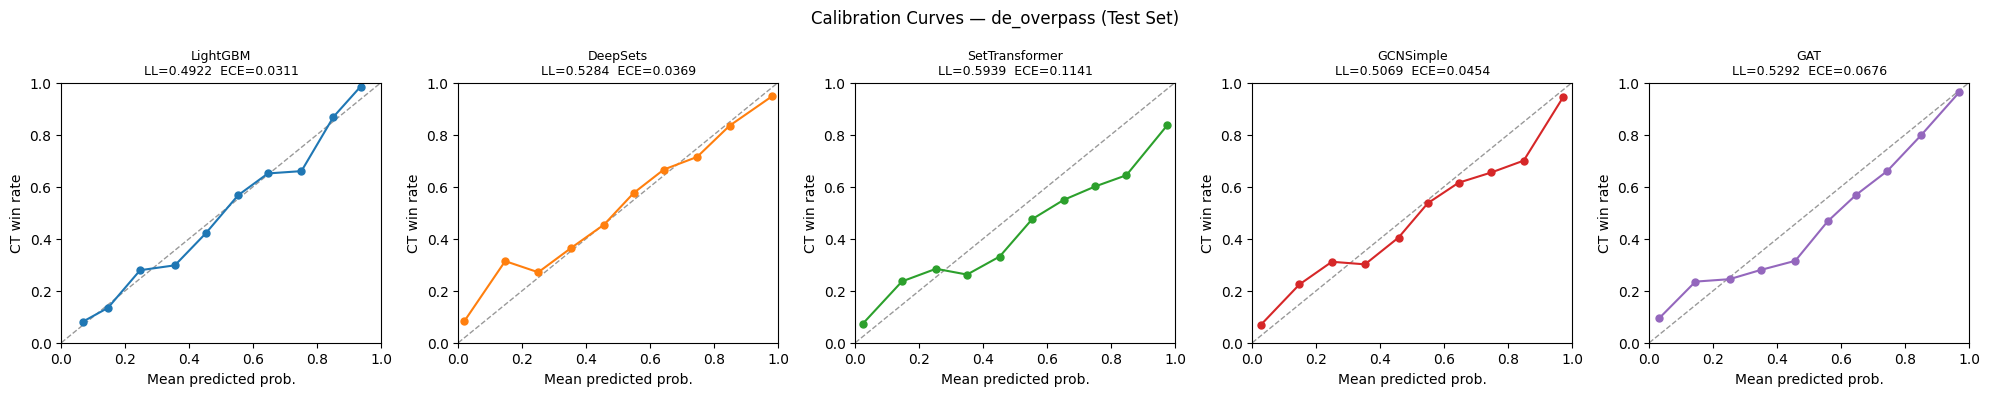

In [24]:
COLORS = {
    'Constant': 'lightgray', 'HP-diff': 'silver',
    'LightGBM': '#1f77b4', 'DeepSets': '#ff7f0e',
    'SetTransformer': '#2ca02c', 'GCNSimple': '#d62728', 'GAT': '#9467bd',
}

def calibration_curve(y_true, y_prob, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1)
    mp, mt = [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        mask = (y_prob >= lo) & (y_prob < hi)
        if mask.sum() > 0:
            mp.append(y_prob[mask].mean()); mt.append(y_true[mask].mean())
    return np.array(mp), np.array(mt)

plot_models = ['LightGBM', 'DeepSets', 'SetTransformer', 'GCNSimple', 'GAT']
fig, axes = plt.subplots(1, len(plot_models), figsize=(4*len(plot_models), 4))
for ax, name in zip(axes, plot_models):
    if name not in test_preds: ax.set_visible(False); continue
    yt, yp = test_preds[name]
    mp, mt = calibration_curve(yt, yp)
    ax.plot([0,1],[0,1],'k--',lw=1,alpha=0.4)
    ax.plot(mp, mt, 'o-', color=COLORS[name], ms=5)
    ax.set_title(f'{name}\nLL={log_loss(yt,yp):.4f}  ECE={compute_ece(yt,yp):.4f}', fontsize=9)
    ax.set_xlabel('Mean predicted prob.'); ax.set_ylabel('CT win rate')
    ax.set_xlim(0,1); ax.set_ylim(0,1)
plt.suptitle(f'Calibration Curves — de_{MAP_NAME} (Test Set)', fontsize=12)
plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / 'fig_calibration.png', dpi=150, bbox_inches='tight')
plt.show()


### 8.3 Time-binned log loss

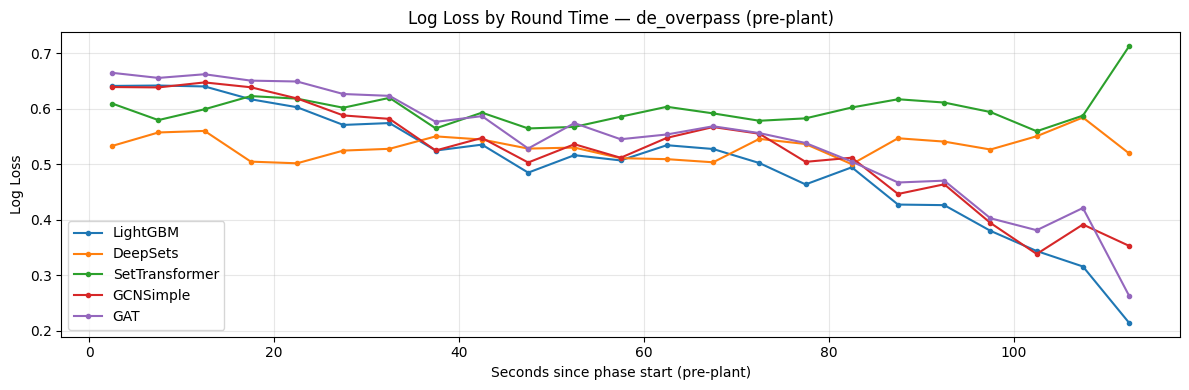

In [25]:
BIN_WIDTH = 5; MAX_TIME = 115
bin_edges   = np.arange(0, MAX_TIME + BIN_WIDTH, BIN_WIDTH)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
pre_plant_mask = (bomb_arr == 0)

fig, ax = plt.subplots(figsize=(12, 4))
# Skip Constant and HP-diff — no time alignment needed, they're trivial
for name in ['LightGBM', 'DeepSets', 'SetTransformer', 'GCNSimple', 'GAT']:
    if name not in test_preds: continue
    yt, yp = test_preds[name]
    if len(yt) != len(time_arr): print(f'  Skipping {name}'); continue
    ll_bins = []
    for lo, hi in zip(bin_edges[:-1], bin_edges[1:]):
        mask = pre_plant_mask & (time_arr >= lo) & (time_arr < hi)
        ll_bins.append(log_loss(yt[mask], yp[mask]) if mask.sum() >= 10 else np.nan)
    ax.plot(bin_centers, ll_bins, '-o', ms=3, lw=1.5, color=COLORS[name], label=name)
ax.set_xlabel('Seconds since phase start (pre-plant)')
ax.set_ylabel('Log Loss')
ax.set_title(f'Log Loss by Round Time — de_{MAP_NAME} (pre-plant)')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / 'fig_ll_by_time.png', dpi=150, bbox_inches='tight')
plt.show()


### 8.4 Late-round log loss

Late pre-plant states (>=85s): 4,245
Post-plant states:                          4,810

Model              Full LL   Late pre-plant LL   Post-plant LL
--------------------------------------------------------------
Constant            7.8752                 n/a             n/a
HP-diff             0.5216                 n/a             n/a
LightGBM            0.4922              0.3857          0.2274
DeepSets            0.5284              0.5434          0.5181
SetTransformer      0.5939              0.6044          0.5871
GCNSimple           0.5069              0.4154          0.2199
GAT                 0.5292              0.4290          0.2358


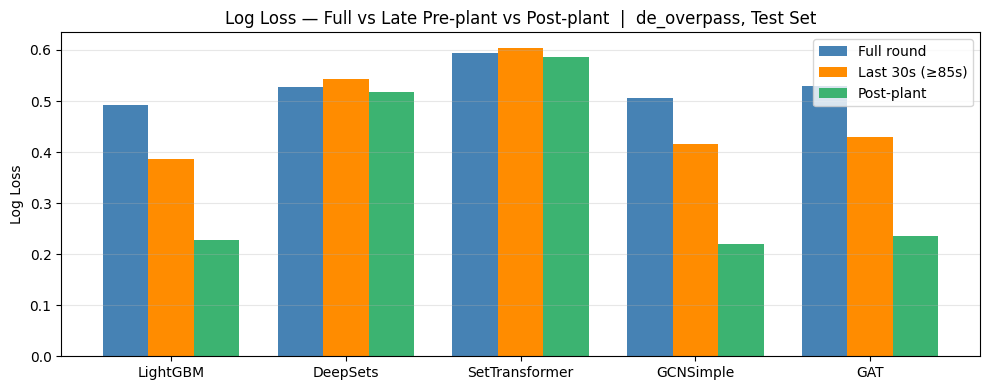

In [26]:
LATE_THRESHOLD = 85
late_mask  = pre_plant_mask & (time_arr >= LATE_THRESHOLD)
plant_mask = (bomb_arr == 1)

print(f'Late pre-plant states (>={LATE_THRESHOLD}s): {late_mask.sum():,}')
print(f'Post-plant states:                          {plant_mask.sum():,}')
print()

late_results = {}
print(f'{"Model":<16}  {"Full LL":>8}  {"Late pre-plant LL":>18}  {"Post-plant LL":>14}')
print('-' * 62)

# Baselines: compute directly (no time alignment needed)
for name in ['Constant', 'HP-diff']:
    yt, yp = test_preds[name]
    ll_f = log_loss(yt, yp)
    # For baselines, time-indexed subsets need separate arrays — skip late/plant breakdown
    late_results[name] = dict(full=ll_f, late=float('nan'), plant=float('nan'))
    print(f'{name:<16}  {ll_f:>8.4f}  {"n/a":>18}  {"n/a":>14}')

for name in ['LightGBM', 'DeepSets', 'SetTransformer', 'GCNSimple', 'GAT']:
    if name not in test_preds: continue
    yt, yp = test_preds[name]
    if len(yt) != len(time_arr): continue
    ll_f = log_loss(yt, yp)
    ll_l = log_loss(yt[late_mask],  yp[late_mask])  if late_mask.sum()  >= 10 else float('nan')
    ll_p = log_loss(yt[plant_mask], yp[plant_mask]) if plant_mask.sum() >= 10 else float('nan')
    late_results[name] = dict(full=ll_f, late=ll_l, plant=ll_p)
    print(f'{name:<16}  {ll_f:>8.4f}  {ll_l:>18.4f}  {ll_p:>14.4f}')

# Bar chart — neural models only (baselines shown as horizontal reference lines)
bar_models = [n for n in ['LightGBM', 'DeepSets', 'SetTransformer', 'GCNSimple', 'GAT']
              if n in late_results]
x = np.arange(len(bar_models)); w = 0.26
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(x-w, [late_results[n]['full']  for n in bar_models], w, label='Full round',   color='steelblue')
ax.bar(x,   [late_results[n]['late']  for n in bar_models], w, label=f'Last 30s (≥{LATE_THRESHOLD}s)', color='darkorange')
ax.bar(x+w, [late_results[n]['plant'] for n in bar_models], w, label='Post-plant',   color='mediumseagreen')
ax.set_xticks(x); ax.set_xticklabels(bar_models)
ax.set_ylabel('Log Loss')
ax.set_title(f'Log Loss — Full vs Late Pre-plant vs Post-plant  |  de_{MAP_NAME}, Test Set')
ax.legend(); ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / 'fig_ll_late_round.png', dpi=150, bbox_inches='tight')
plt.show()


### 8.5 Round win probability trace

In [26]:
list(test_data.keys())[17]

'FISSURE Playground 1_betboom-vs-heroic-m3-anubis'

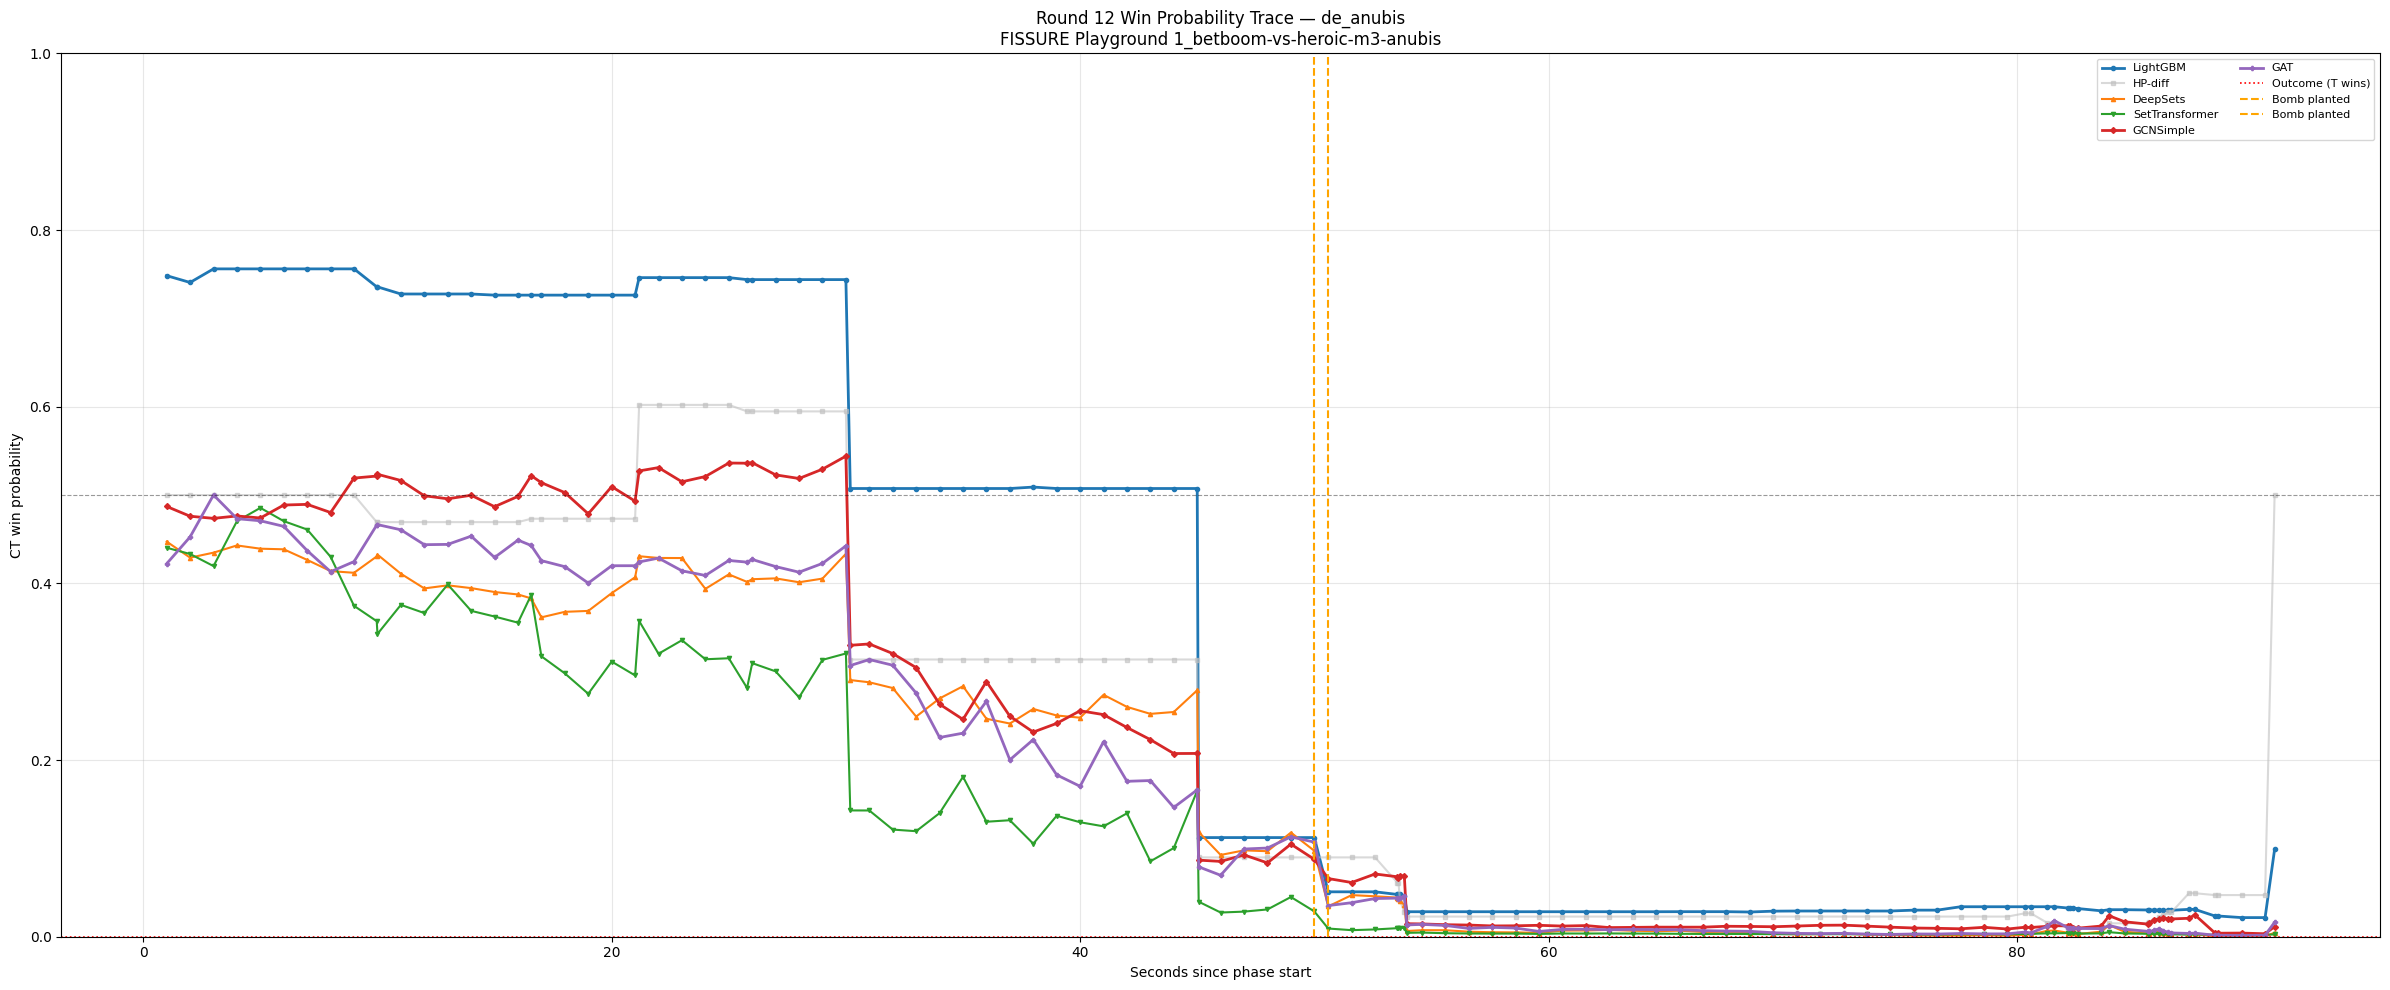

States in round: 115
Outcome: T wins
Bomb planted: yes


In [27]:
# ── Round win probability trace — all models ─────────────────────────────
MATCH_KEY = list(test_data.keys())[17]   # change to a specific match key
ROUND_NUM = 12
match = test_data[MATCH_KEY]

# Collect all state indices belonging to this round
round_idx = [i for i, df_row in enumerate(match['df'])
             if df_row.get('roundNum') == ROUND_NUM]

if not round_idx:
    print(f'Round {ROUND_NUM} not found in {MATCH_KEY}')
else:
    # Build a continuous time axis: pre-plant uses secondsSincePhaseStart directly,
# post-plant adds the pre-plant duration so they appear after on the x-axis
    preplant_duration = max(
        (float(match['df'][i].get('secondsSincePhaseStart', 0))
        for i in round_idx
        if not match['df'][i].get('bombPlanted', 0)),
        default=0.0
    )

    times = []
    for i in round_idx:
        t    = float(match['df'][i].get('secondsSincePhaseStart', 0))
        bomb = int(match['df'][i].get('bombPlanted', 0))
        times.append(preplant_duration + t if bomb else t)
    bombs  = [int(match['df'][i].get('bombPlanted', 0))              for i in round_idx]
    y_true = match['Y'][round_idx[0]]

    # ── LightGBM ─────────────────────────────────────────────────────────
    X_round = pd.DataFrame([match['df'][i] for i in round_idx])
    drop_cols = [c for c in ['tick', 'roundNum', 'ctWin'] if c in X_round.columns]
    X_round = X_round.drop(columns=drop_cols).fillna(0)
    lgbm_probs = lgbm_model.predict(X_round)

    # ── HP-diff baseline ─────────────────────────────────────────────────
    delta_h    = X_round['ctHp'].values - X_round['tHp'].values
    hpdiff_round = np.clip(1 / (1 + np.exp(-delta_h / tau_opt)), 1e-7, 1 - 1e-7)

    # ── DeepSets / SetTransformer ─────────────────────────────────────────
    # Load the normaliser that was fitted on the training set
    normaliser = datasets['set']['normaliser']

    round_set_probs = {}
    for model_name, set_model in [('DeepSets', deepsets_model),
                                   ('SetTransformer', settransformer_model)]:
        set_model.eval()
        preds = []
        with torch.no_grad():
            for i in round_idx:
                # match['X'][i] is a list of player vectors (already normalised
                # by SetNormaliser during build_datasets — re-apply manually here
                # since we're going directly from raw JSON)
                x_raw = np.array(match['X'][i], dtype=np.float32)   # (N, 32)
                x_norm = normaliser.transform(x_raw)                  # (N, 32)
                xb = torch.tensor(x_norm, dtype=torch.float32).unsqueeze(0).to(DEVICE)  # (1, N, 32)
                logit = set_model(xb)
                preds.append(torch.sigmoid(logit).item())
        round_set_probs[model_name] = np.array(preds)

    # ── GCNSimple / GAT ───────────────────────────────────────────────────
    round_graph_probs = {}
    for model_name, graph_model in [('GCNSimple', gcn_simple_model),
                                     ('GAT', gat_model)]:
        graph_model.eval()
        preds = []
        with torch.no_grad():
            for i in round_idx:
                g = match['GNN'][i]
                x          = torch.tensor(g['x'],          dtype=torch.float32)
                edge_index = torch.tensor(g['edge_index'],  dtype=torch.long)
                edge_attr  = torch.tensor(g['edge_attr'],   dtype=torch.float32)
                # Normalise node features with the same SetNormaliser
                # x = torch.tensor(
                #     normaliser.transform(x.numpy()), dtype=torch.float32
                # )
                data = Data(x=x, edge_index=edge_index, edge_attr=edge_attr,
                            y=torch.tensor([y_true], dtype=torch.float32))
                data = data.to(DEVICE)
                # Wrap in a single-graph batch (global_mean_pool needs batch vector)
                from torch_geometric.data import Batch
                batch = Batch.from_data_list([data.cpu()]).to(DEVICE)
                logit = graph_model(batch)
                preds.append(torch.sigmoid(logit).item())
        round_graph_probs[model_name] = np.array(preds)

    # ── Plot ──────────────────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(24, 10))

    ax.plot(times, lgbm_probs,              '-o',  ms=3, lw=2,   color=COLORS['LightGBM'],      label='LightGBM')
    ax.plot(times, hpdiff_round,            '-s',  ms=3, lw=1.5, color=COLORS['HP-diff'],        label='HP-diff', alpha=0.6)
    ax.plot(times, round_set_probs['DeepSets'],    '-^', ms=3, lw=1.5, color=COLORS['DeepSets'],       label='DeepSets')
    ax.plot(times, round_set_probs['SetTransformer'], '-v', ms=3, lw=1.5, color=COLORS['SetTransformer'], label='SetTransformer')
    ax.plot(times, round_graph_probs['GCNSimple'], '-D', ms=3, lw=2,   color=COLORS['GCNSimple'],     label='GCNSimple')
    ax.plot(times, round_graph_probs['GAT'],       '-P', ms=3, lw=2,   color=COLORS['GAT'],           label='GAT')

    ax.axhline(0.5,    color='k',                          lw=0.8, ls='--', alpha=0.4)
    ax.axhline(y_true, color='green' if y_true == 1 else 'red', lw=1.2, ls=':',
               label=f'Outcome ({"CT wins" if y_true == 1 else "T wins"})')

    plant_idx = next((i for i, b in enumerate(bombs) if b == 1), None)
    if plant_idx is not None:
        ax.axvline(times[plant_idx], color='orange', lw=1.5, ls='--', label='Bomb planted')
    ax.axvline(preplant_duration, color='orange', lw=1.5, ls='--', label='Bomb planted')
    ax.set_xlabel('Seconds since round start (post-plant time offset)')
    ax.set_xlabel('Seconds since phase start')
    ax.set_ylabel('CT win probability')
    ax.set_title(f'Round {ROUND_NUM} Win Probability Trace — de_{MAP_NAME}\n{MATCH_KEY}')
    ax.set_ylim(0, 1)
    ax.legend(fontsize=8, ncol=2)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(CHECKPOINT_DIR / f'fig_round_trace_r{ROUND_NUM}.png', dpi=150, bbox_inches='tight')
    plt.show()

    print(f'States in round: {len(round_idx)}')
    print(f'Outcome: {"CT wins" if y_true == 1 else "T wins"}')
    print(f'Bomb planted: {"yes" if plant_idx is not None else "no"}')

## 9. Temporal GNN  *(run in a separate session)*

RAM-heavy — run alone on A100 if available (removes max_seq_len=80 cap).
Use `lr_temporal=3e-4` and `grad_clip_temporal=0.5` from the start.

In [ ]:
from torch.utils.data import DataLoader as TorchDataLoader

temporal_train = TemporalGraphDataset(train_data, max_len=CFG['max_seq_len'])
temporal_val   = TemporalGraphDataset(val_data,   max_len=CFG['max_seq_len'])
temporal_test  = TemporalGraphDataset(test_data,  max_len=CFG['max_seq_len'])
print(f'Temporal: train={len(temporal_train)} val={len(temporal_val)} test={len(temporal_test)} rounds')


In [ ]:
tgnn_ckpt = CHECKPOINT_DIR / 'temporal_gnn.pt'
temporal_model = TemporalGNN(hidden=128).to(DEVICE)

if tgnn_ckpt.exists():
    print('  Checkpoint found → loading')
    temporal_model.load_state_dict(torch.load(tgnn_ckpt, map_location=DEVICE))
    temporal_model.eval()
else:
    optim = Adam(temporal_model.parameters(),
                 lr=CFG['lr_temporal'], weight_decay=CFG['weight_decay'])
    crit  = nn.BCEWithLogitsLoss()
    train_loader = TorchDataLoader(temporal_train, batch_size=CFG['batch_size'],
                                   shuffle=True, collate_fn=temporal_collate_fn)
    val_loader   = TorchDataLoader(temporal_val,   batch_size=CFG['batch_size'],
                                   shuffle=False, collate_fn=temporal_collate_fn)
    best_val, best_ep, no_improve = float('inf'), 0, 0

    for ep in range(1, CFG['epochs'] + 1):
        temporal_model.train()
        tot_loss, tot_n = 0.0, 0
        for ts_batches, masks, labels in train_loader:
            lbl = labels.float().unsqueeze(1).to(DEVICE)
            optim.zero_grad()
            loss = crit(temporal_model(ts_batches, masks, lbl.size(0)), lbl)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(temporal_model.parameters(), CFG['grad_clip_temporal'])
            optim.step()
            tot_loss += loss.item() * lbl.size(0); tot_n += lbl.size(0)

        temporal_model.eval()
        val_probs, val_trues = [], []
        with torch.no_grad():
            for ts_batches, masks, labels in val_loader:
                lbl = labels.float().unsqueeze(1).to(DEVICE)
                logits = temporal_model(ts_batches, masks, lbl.size(0))
                val_probs.append(torch.sigmoid(logits).cpu().numpy().flatten())
                val_trues.append(labels.numpy().flatten())
        val_ll = log_loss(np.concatenate(val_trues), np.concatenate(val_probs))
        print(f'  Epoch {ep:3d}  train LL={tot_loss/tot_n:.4f}  val LL={val_ll:.4f}')

        if val_ll < best_val:
            best_val, best_ep, no_improve = val_ll, ep, 0
            torch.save(temporal_model.state_dict(), tgnn_ckpt)
        else:
            no_improve += 1
            if no_improve >= CFG['patience']:
                print(f'  Early stop at epoch {ep} (best epoch {best_ep}, val LL={best_val:.4f})')
                break

    temporal_model.load_state_dict(torch.load(tgnn_ckpt, map_location=DEVICE))
    temporal_model.eval()


In [ ]:
test_loader = TorchDataLoader(temporal_test, batch_size=CFG['batch_size'],
                               shuffle=False, collate_fn=temporal_collate_fn)
tgnn_probs, tgnn_trues = [], []
with torch.no_grad():
    for ts_batches, masks, labels in test_loader:
        lbl = labels.float().unsqueeze(1).to(DEVICE)
        logits = temporal_model(ts_batches, masks, lbl.size(0))
        tgnn_probs.append(torch.sigmoid(logits).cpu().numpy().flatten())
        tgnn_trues.append(labels.numpy().flatten())

tgnn_y, tgnn_p = np.concatenate(tgnn_trues), np.concatenate(tgnn_probs)
evaluate_numpy(tgnn_y, tgnn_p, 'TemporalGNN/test')
test_preds['TemporalGNN'] = (tgnn_y, tgnn_p)
print('TemporalGNN added to test_preds.')
